In [1]:
import pathlib

import navis.interfaces.neuprint as neu
from matplotlib import pyplot as plt

import el_hd_plasticity.connectomics as cn
from el_hd_plasticity.connectomics import connectivity, plotting

plt.rcParams['pdf.fonttype'] = 42

%load_ext autoreload
%autoreload 2
%matplotlib inline

figfolder = pathlib.Path('/media/mplitt/SSD_storage/fig_scratch/EL_connectomics')
figfolder.mkdir(parents=True, exist_ok=True)
syndist_folder = figfolder / 'syn_distances'      # written by el_hd_plasticity.connectomics.run_*synapse_distance
client = cn.npt_client()

## Inputs onto ER neurons

In [2]:
pre_query = neu.NeuronCriteria(type=['EL', 'EPG', 'PEG', 'PEN_a.*', 'PEN_b.*'], outputRois=['EB'], roi_req='any')
post_query = neu.NeuronCriteria(type=['ER1.*', 'ER2.*', 'ER3.*', 'ER4.*'], inputRois=['EB'], roi_req='any')

neuron_df, conn_df = connectivity.fetch_connections(pre_query, post_query)
conn_df = connectivity.add_relative_weights(
    conn_df, neuron_df,
    presynapse_counts=connectivity.fetch_synapse_counts(conn_df['bodyId_pre'].unique(), side='pre'),
    postsynapse_counts=connectivity.fetch_synapse_counts(conn_df['bodyId_post'].unique(), side='post'))

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/11 [00:00<?, ?it/s]

  0%|          | 0/24 [00:00<?, ?it/s]

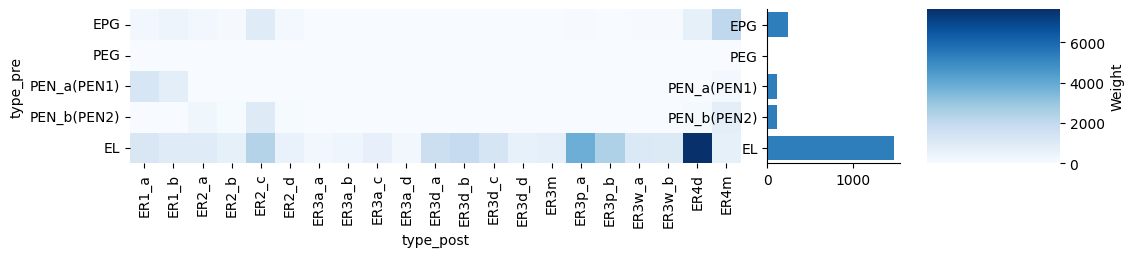

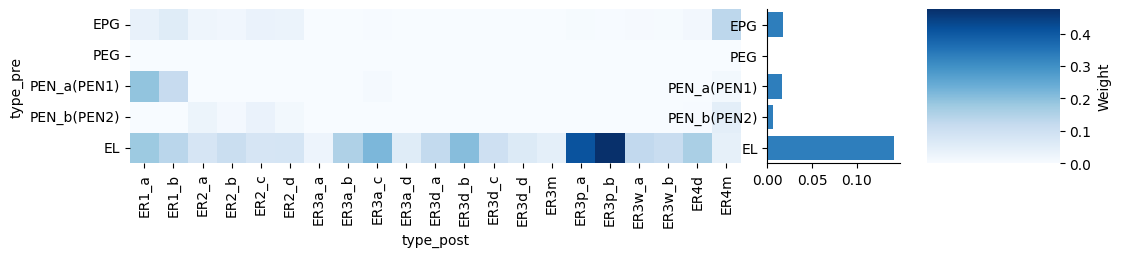

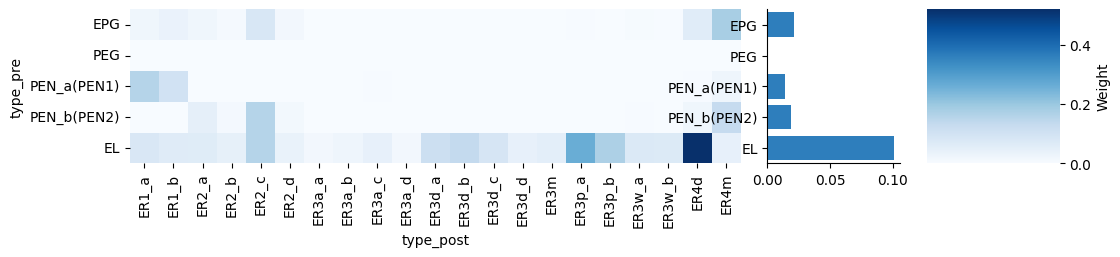

In [3]:
for weight_col in ('weight', 'relative_weight', 'pcnt_output'):
    fig, axs = plotting.plot_er_inputs_with_marginal(conn_df, weight_col=weight_col)

## Connectivity between EL, EPG and ER2/4d

In [4]:
query = neu.NeuronCriteria(type=['EL', 'EPG', 'ER4d', 'ER2.*'])
query_neuron_df, _ = neu.fetch_neurons(query)
_, conn_df = connectivity.fetch_connections(query, query)

type_counts = connectivity.fetch_type_synapse_counts(query_neuron_df['type'].unique())
type_table, n_neurons = connectivity.type_connectivity(conn_df, query_neuron_df, type_counts)
type_table

  0%|          | 0/1 [00:00<?, ?it/s]

0it [00:00, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

... (7 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

,type_pre,type_post,weight,relative_weight,pcnt_output,nrn_weight
0,EL,EPG,5634,0.035715,0.383161,122.478261
1,EPG,EL,9311,0.122442,0.812762,517.277778
2,EL,ER2/4d,12145,0.120118,0.825966,181.268657
3,EPG,ER2/4d,2187,0.021630,0.190904,32.641791
4,ER2/4d,EL,12424,0.163379,0.383895,690.222222
5,ER2/4d,EPG,34026,0.215697,1.051386,739.695652


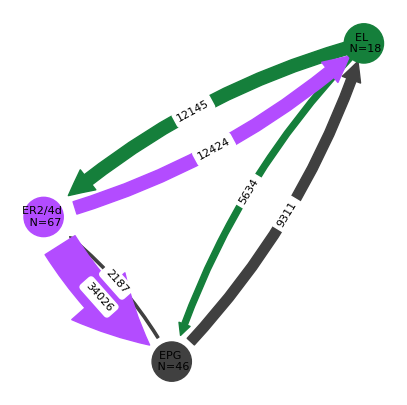

In [5]:
graph = connectivity.connectivity_graph(type_table, n_neurons)
colors = {'EL': plt.cm.Greens(.8), 'EPG': plt.cm.Greys(.8), 'ER2/4d': plt.cm.cool(.7)}
pos = {'ER2/4d': [.2, .4], 'EL': [.7, .7], 'EPG': [.4, .15]}

fig, ax = plotting.plot_connectivity_graph(graph, colors, pos, edge_attr='weight')
# fig.savefig(figfolder / 'connectivity_graph.pdf')